# ForestEar: acoustic threat detection for forest protection

**Course:** BSE - Machine Learning Pipeline (summative) · **Data type:** sound (not tabular)

**Problem.** Illegal logging, fires and low-flying aircraft in protected forests (think Nyungwe or Gishwati) are
hard to spot from the ground, but they are *loud*. A cheap microphone node that listens in 5-second windows and
recognises the sound of a **chainsaw**, **crackling fire** or **helicopter** against everyday forest and village
sounds could raise an alert in seconds. This notebook builds and evaluates the classifier behind that idea.

**What this notebook covers (matches the rubric):**
1. Data acquisition  2. Data processing  3. Model creation (baseline, then optimised)  4. Model testing
5. Retraining readiness  6. Prediction function used by the API.

The production code lives in `src/`; this notebook imports it so that what is evaluated here is exactly what is deployed.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import keras
from IPython.display import display, Markdown

from src import config as C, preprocessing as P, model as M, insights as I
from src.data_acquisition import acquire

keras.utils.set_random_seed(C.SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
TEAL, ORANGE, INK, GREY = "#1F6F66", "#D4452B", "#14211F", "#8A9A96"
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print("keras", keras.__version__, "| root:", ROOT)

I0000 00:00:1795439679.061756     105 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795439684.697104     105 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


keras 3.15.1 | root: /home/claude/forest_ear


## 1. Data acquisition

We use **ESC-10**, the 10-class subset of the ESC-50 environmental sound corpus (Piczak, 2015: 400 clips of 5 s from
Freesound). `acquire()` downloads the corpus from GitHub, keeps the 10 classes, converts every clip to
16 kHz / mono / 16-bit WAV and splits it **by the dataset's official folds**:

| Split | Folds | Used for |
|---|---|---|
| train | 1-3 | fitting weights |
| validation | 4 | early stopping, hyper-parameter choice |
| test | 5 | final numbers, never touched before the end |

Splitting by fold matters: clips cut from the same original recording share a fold, so no near-duplicate leaks
from train into test.

Dataset already present - use --force to rebuild.
{'train': {'chainsaw': 32, 'clock_tick': 32, 'crackling_fire': 32, 'crying_baby': 32, 'dog': 32, 'helicopter': 32, 'rain': 32, 'rooster': 32, 'sea_waves': 32, 'sneezing': 32}, 'test': {'chainsaw': 8, 'clock_tick': 8, 'crackling_fire': 8, 'crying_baby': 8, 'dog': 8, 'helicopter': 8, 'rain': 8, 'rooster': 8, 'sea_waves': 8, 'sneezing': 8}}


,train,test,total
chainsaw,32,8,40
clock_tick,32,8,40
crackling_fire,32,8,40
crying_baby,32,8,40
dog,32,8,40
helicopter,32,8,40
rain,32,8,40
rooster,32,8,40
sea_waves,32,8,40
sneezing,32,8,40


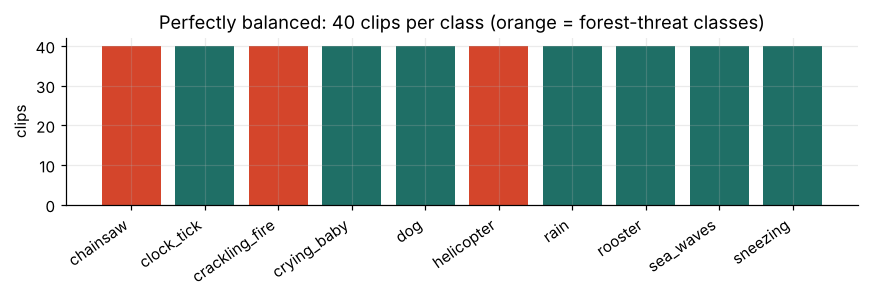

In [2]:
summary = acquire()          # no-op when data/ is already populated
counts = pd.DataFrame(summary).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
display(counts)
fig, ax = plt.subplots(figsize=(8, 2.8))
colors = [ORANGE if c in C.ALERT_CLASSES else TEAL for c in counts.index]
ax.bar(counts.index, counts["total"], color=colors); ax.set_ylabel("clips")
ax.set_title("Perfectly balanced: 40 clips per class (orange = forest-threat classes)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.savefig(FIG / "class_balance.png"); plt.show()

## 2. Exploring the sounds

Before modelling, what does each class look like? A log-mel spectrogram shows time on the x-axis, pitch on the
y-axis (mel scale) and loudness as colour.

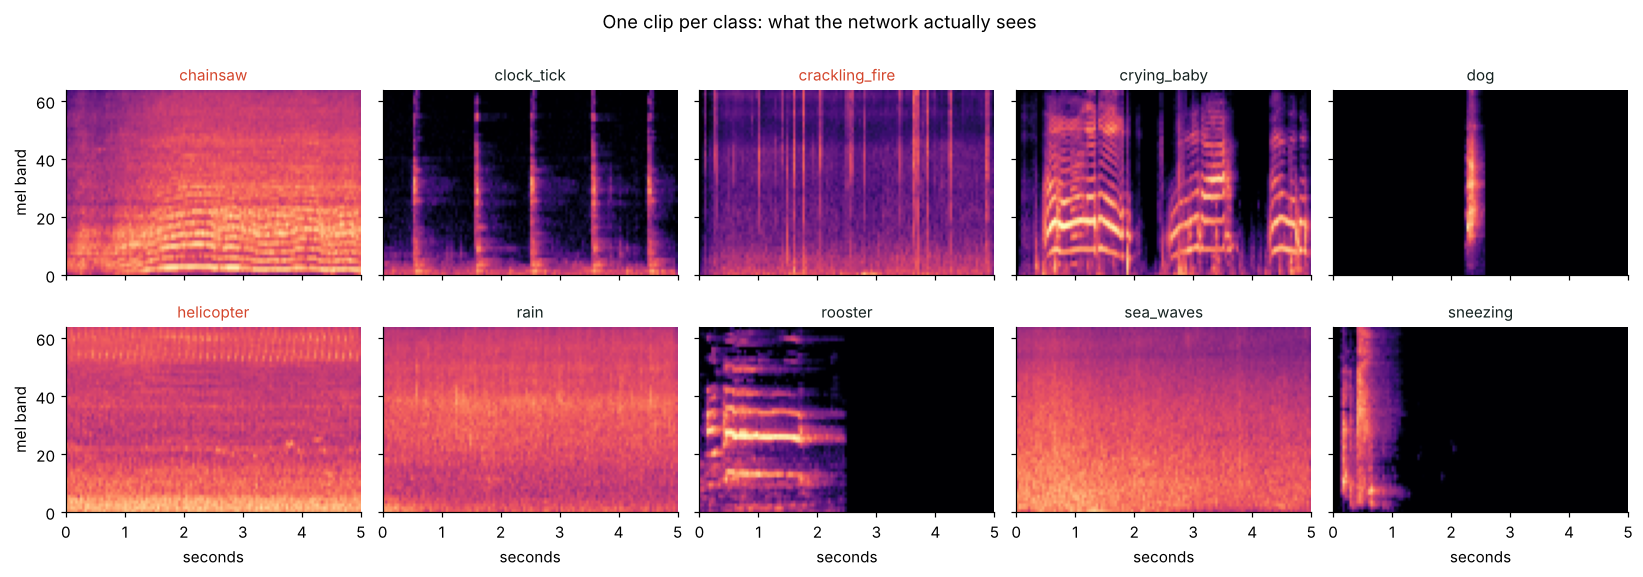

In [3]:
train_clips = P.list_clips(C.TRAIN_DIR)
first = {}
for p, c in train_clips:
    first.setdefault(c, p)
fig, axes = plt.subplots(2, 5, figsize=(15, 5.2), sharex=True, sharey=True)
for ax, (c, p) in zip(axes.ravel(), sorted(first.items())):
    S = P.features_from_source(str(p))
    ax.imshow(S, origin="lower", aspect="auto", cmap="magma", extent=[0, 5, 0, C.N_MELS], vmin=-60, vmax=25)
    ax.set_title(c, color=ORANGE if c in C.ALERT_CLASSES else INK, fontsize=10); ax.grid(False)
for ax in axes[:, 0]: ax.set_ylabel("mel band")
for ax in axes[1]: ax.set_xlabel("seconds")
fig.suptitle("One clip per class: what the network actually sees", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "spectrogram_gallery.png"); plt.show()

### Three features, three stories

We measure acoustic features on every clip, then ask what each one says about the classes.
Interpretations below are generated from the computed numbers, so they cannot drift away from the data.

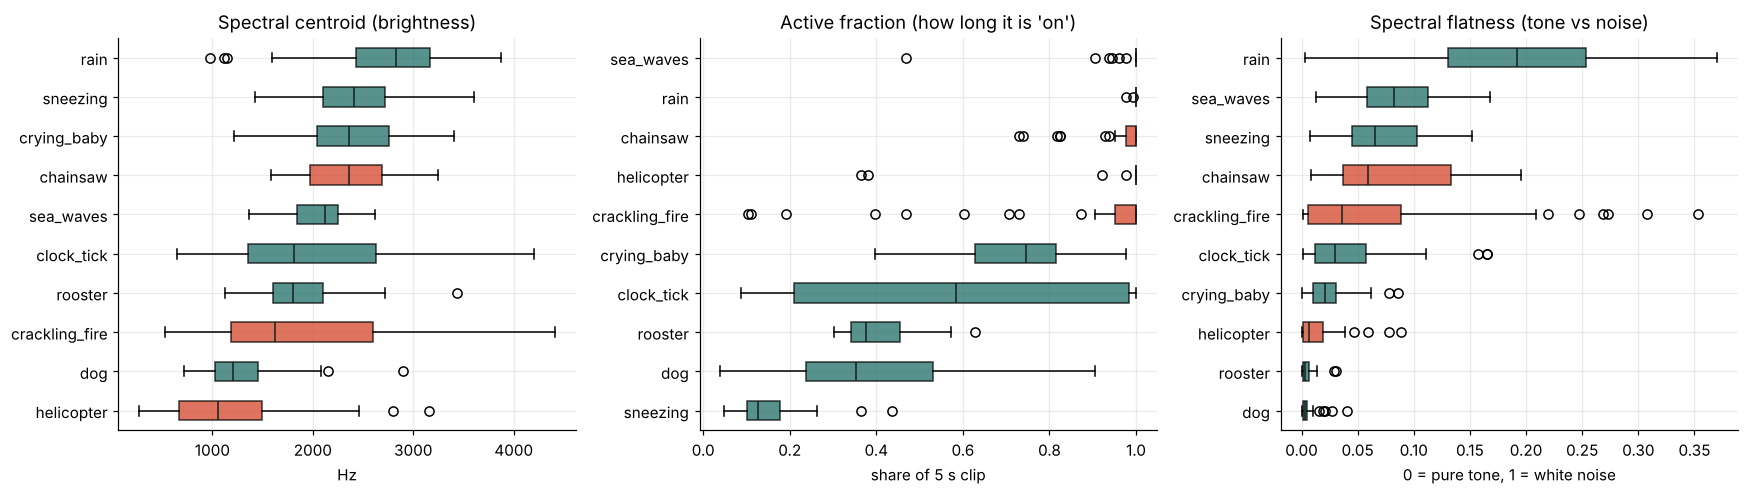

**Brightness: where the energy sits.** Spectral centroid is the 'centre of mass' of a sound's spectrum. rain is the brightest (2.7 kHz, broadband hiss) while helicopter is the darkest (1.2 kHz, low rotor thump). Chainsaw (2.4 kHz), crying baby (2.4 kHz) and sneezing (2.4 kHz) all land at almost the same value, so brightness alone cannot separate them. The model needs the time-frequency pattern, which is why we feed it spectrograms.

**Duration: how long the sound is 'on'.** Share of the 5 s clip within 25 dB of its loudest moment. Rain (100%), sea waves (98%), chainsaw (97%) and helicopter (97%) are continuous; sneezing (15%), dog (39%) and rooster (40%) are short bursts. Two of the three forest-threat classes (chainsaw, helicopter) are sustained, which is good news for a field sensor: a few seconds of audio is enough to catch them.

**Texture: tonal versus noise-like.** Spectral flatness is near 0 for pure tones and near 1 for white noise. Rooster (0.005) and dog (0.006) are tonal and harmonic; rain (0.183) is the most noise-like. Chainsaw (0.084) and sea waves (0.084) are also noise-like and, like rain, are 'always on', so the continuous noisy sounds are the group we expect to be hardest to tell apart. The confusion matrix after training tests that.

In [4]:
df = I.feature_table()
stories = I.make_stories(df)
I.write_insights(df, stories)      # the web UI reads this same file
order = lambda col: df.groupby("label")[col].median().sort_values().index.tolist()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, col, ttl, unit in zip(axes, ["centroid_hz", "active_fraction", "flatness"],
        ["Spectral centroid (brightness)", "Active fraction (how long it is 'on')", "Spectral flatness (tone vs noise)"],
        ["Hz", "share of 5 s clip", "0 = pure tone, 1 = white noise"]):
    o = order(col)
    bp = ax.boxplot([df.loc[df.label == c, col] for c in o], vert=False, tick_labels=o, patch_artist=True,
                    medianprops=dict(color=INK))
    for patch, c in zip(bp["boxes"], o):
        patch.set_facecolor(ORANGE if c in C.ALERT_CLASSES else TEAL); patch.set_alpha(.75)
    ax.set_title(ttl); ax.set_xlabel(unit)
plt.tight_layout(); plt.savefig(FIG / "feature_stories.png"); plt.show()
for s in stories:
    display(Markdown(f"**{s['title']}.** {s['text']}"))

## 3. Data processing

Pipeline applied to every clip (training, testing, API uploads and retraining all share `src/preprocessing.py`):

1. **Decode** to mono and **resample** to 16 kHz.
2. **Fix length** to exactly 5 s: shorter clips are padded with silence; longer uploads keep their **loudest** 5 s window.
3. **Log-mel spectrogram**: 1024-point FFT, hop 640 samples (40 ms), 64 mel bands from 20 Hz to 8 kHz, converted to dB
   with a -100 dB floor. Result: a `64 x 126` image per clip.
4. **Normalise inside the model** (fixed rescale + batch-norm), so the API needs no stored scaler.

For training only we add **augmentation** directly on the spectrogram: random time roll, loudness shift (-12..+6 dB, so
quiet field recordings are not out-of-distribution), and SpecAugment frequency/time masks.

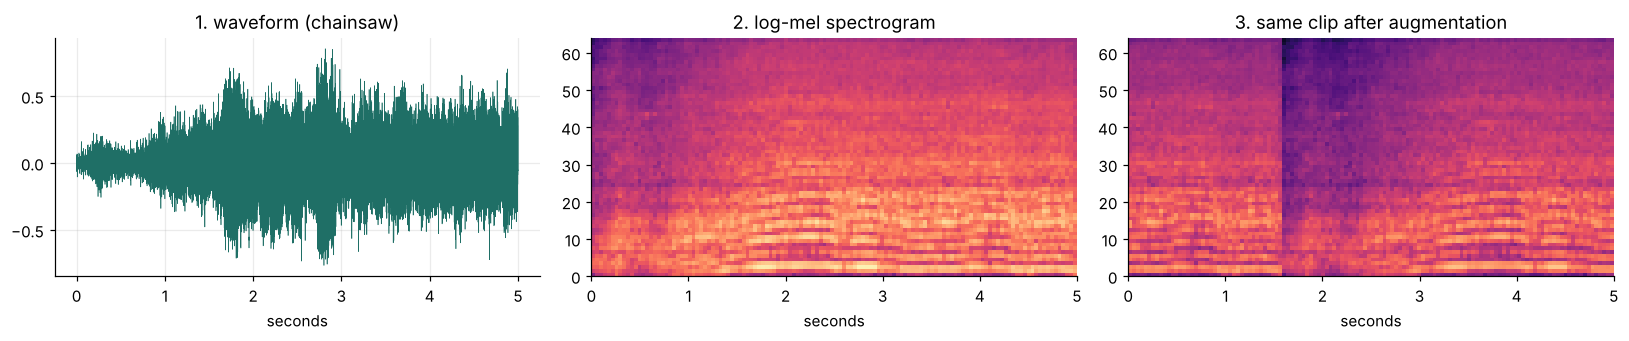

classes: ['chainsaw', 'clock_tick', 'crackling_fire', 'crying_baby', 'dog', 'helicopter', 'rain', 'rooster', 'sea_waves', 'sneezing']
train (240, 64, 126)  validation (80, 64, 126)  test (80, 64, 126)


In [5]:
p = first["chainsaw"]
y_wav = P.fit_length(P.load_waveform(str(p)))
S = P.logmel(y_wav)
S_aug = P.augment(S, np.random.default_rng(3))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
ax[0].plot(np.arange(len(y_wav)) / C.SAMPLE_RATE, y_wav, color=TEAL, lw=.4); ax[0].set_title("1. waveform (chainsaw)"); ax[0].set_xlabel("seconds")
for a, img, t in zip(ax[1:], [S, S_aug], ["2. log-mel spectrogram", "3. same clip after augmentation"]):
    a.imshow(img, origin="lower", aspect="auto", cmap="magma", extent=[0, 5, 0, 64], vmin=-60, vmax=25); a.set_title(t); a.grid(False); a.set_xlabel("seconds")
plt.tight_layout(); plt.savefig(FIG / "preprocessing_steps.png"); plt.show()

X, paths, labels = P.build_features(train_clips)
classes = sorted(set(labels)); n = len(classes)
y = P.encode_labels(labels, classes)
is_val = np.array([P.is_validation(q) for q in paths])
Xtr, ytr, Xva, yva = X[~is_val], y[~is_val], X[is_val], y[is_val]
test_clips = P.list_clips(C.TEST_DIR)
Xte, _, lte = P.build_features(test_clips); yte = P.encode_labels(lte, classes)
print(f"classes: {classes}")
print(f"train {Xtr.shape}  validation {Xva.shape}  test {Xte.shape}")

## 4. Model creation

### 4a. Baseline: a *vanilla* CNN
Same architecture, but with **no** regularisation, no dropout, no augmentation, no early stopping and a fixed 40 epochs.
It tells us how much the optimisation work below is really worth.

In [6]:
keras.utils.set_random_seed(C.SEED)
base = M.compile_model(M.build_cnn(n, base_filters=16, dropout=0.0, l2=0.0), lr=2e-3, label_smoothing=0.0)
tr = M.AugmentedBatches(Xtr, ytr, n, 16, augment_on=False)
va = M.AugmentedBatches(Xva, yva, n, 32, augment_on=False)
t0 = time.time(); hist_base = base.fit(tr, validation_data=va, epochs=40, verbose=0).history
base_val = M.evaluate(base, Xva, yva, classes)
print(f"baseline trained in {time.time()-t0:.0f}s | train acc {hist_base['accuracy'][-1]:.3f} | "
      f"val acc {base_val['accuracy']:.3f} | val loss {base_val['loss']:.3f}")

baseline trained in 90s | train acc 1.000 | val acc 0.825 | val loss 0.587


### 4b. Optimisation

| Technique | Where |
|---|---|
| L2 weight regularisation + spatial dropout + dense dropout | `build_cnn` |
| Batch normalisation | every conv block |
| Label smoothing (0.05) | loss |
| Data augmentation (time shift, gain, SpecAugment) with tunable strength | `AugmentedBatches` |
| Adam + **ReduceLROnPlateau** | `fit` |
| **Early stopping** (restore best weights) | `fit` |
| **Hyper-parameter tuning**: random search, 6 trials over width, dropout, L2, learning rate and augmentation strength | below |

In [7]:
rng = np.random.default_rng(7)
space = dict(base_filters=[16, 24], dropout=[0.2, 0.3, 0.4], l2=[1e-4, 3e-4],
             lr=[1e-3, 2e-3], aug=[0.0, 0.5], batch_size=[16])
trials = []
for t in range(6):
    params = {k: v[int(rng.integers(len(v)))] for k, v in space.items()}
    keras.utils.set_random_seed(C.SEED + t)
    m = M.compile_model(M.build_cnn(n, **params), **params)
    hist, secs = M.fit(m, Xtr, ytr, Xva, yva, n, epochs=80, params=params, patience=15)
    v = M.evaluate(m, Xva, yva, classes)
    trials.append(dict(trial=t + 1, **params, epochs=len(hist["loss"]), val_loss=v["loss"], val_acc=v["accuracy"],
                       val_f1=v["f1_macro"], seconds=round(secs), model=m, hist=hist, params=params))
    print(f"trial {t+1}: {params} -> val acc {v['accuracy']:.3f}, loss {v['loss']:.3f} ({secs:.0f}s)")
res = pd.DataFrame([{k: v for k, v in r.items() if k not in ("model", "hist", "params")} for r in trials])
display(res.sort_values(["val_acc", "val_loss"], ascending=[False, True]).round(3).reset_index(drop=True))
best = min(trials, key=lambda r: (-round(r["val_acc"], 3), r["val_loss"]))   # validation accuracy, loss breaks ties
print("\nselected trial", best["trial"], best["params"])

trial 1: {'base_filters': 24, 'dropout': 0.3, 'l2': 0.0003, 'lr': 0.002, 'aug': 0.5, 'batch_size': 16} -> val acc 0.938, loss 0.305 (246s)


trial 2: {'base_filters': 24, 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.001, 'aug': 0.0, 'batch_size': 16} -> val acc 0.850, loss 0.468 (234s)


trial 3: {'base_filters': 16, 'dropout': 0.4, 'l2': 0.0003, 'lr': 0.001, 'aug': 0.0, 'batch_size': 16} -> val acc 0.825, loss 0.689 (185s)


trial 4: {'base_filters': 24, 'dropout': 0.2, 'l2': 0.0003, 'lr': 0.001, 'aug': 0.0, 'batch_size': 16} -> val acc 0.925, loss 0.317 (210s)


trial 5: {'base_filters': 24, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'aug': 0.5, 'batch_size': 16} -> val acc 0.950, loss 0.273 (196s)


trial 6: {'base_filters': 16, 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.001, 'aug': 0.5, 'batch_size': 16} -> val acc 0.900, loss 0.582 (192s)


,trial,base_filters,dropout,l2,lr,aug,batch_size,epochs,val_loss,val_acc,val_f1,seconds
0,5,24,0.2,0.0,0.001,0.5,16,70,0.273,0.950,0.950,196
1,1,24,0.3,0.0,0.002,0.5,16,80,0.305,0.938,0.937,246
2,4,24,0.2,0.0,0.001,0.0,16,80,0.317,0.925,0.923,210
3,6,16,0.4,0.0,0.001,0.5,16,80,0.582,0.900,0.897,192
4,2,24,0.4,0.0,0.001,0.0,16,80,0.468,0.850,0.845,234
5,3,16,0.4,0.0,0.001,0.0,16,80,0.689,0.825,0.819,185



selected trial 5 {'base_filters': 24, 'dropout': 0.2, 'l2': 0.0001, 'lr': 0.001, 'aug': 0.5, 'batch_size': 16}


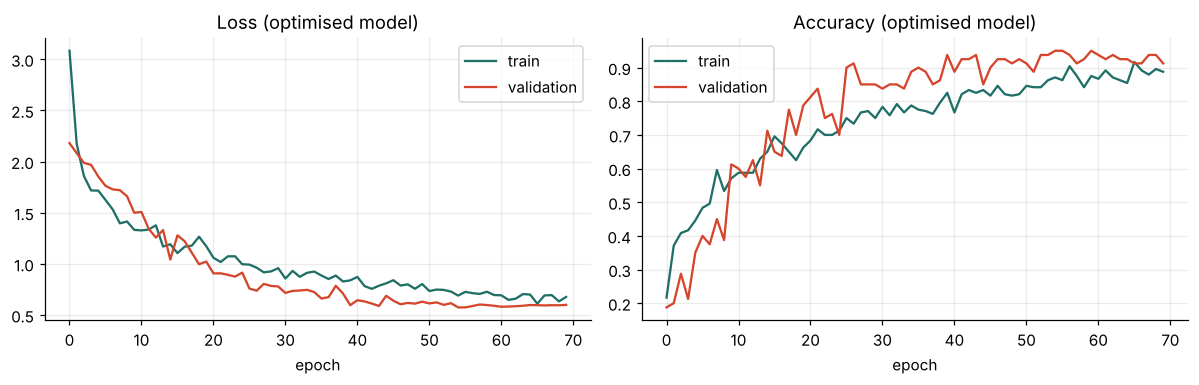

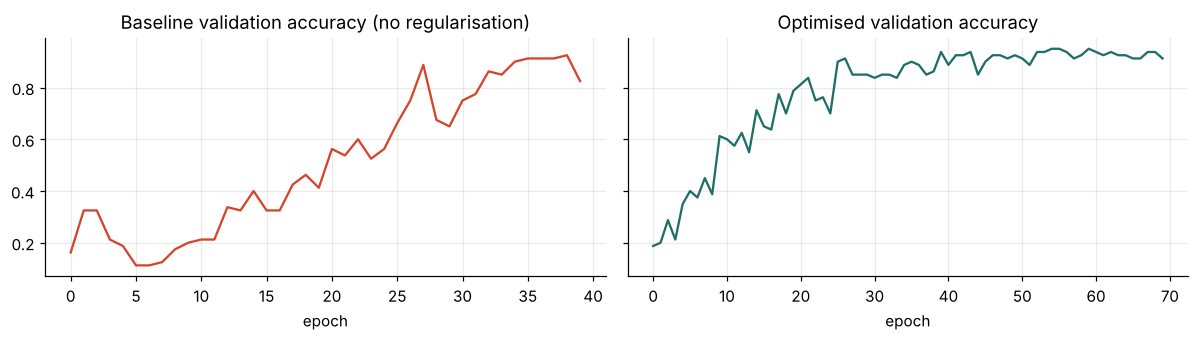

In [8]:
h = best["hist"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(h["loss"], color=TEAL, label="train"); ax[0].plot(h["val_loss"], color=ORANGE, label="validation"); ax[0].set_title("Loss (optimised model)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(h["accuracy"], color=TEAL, label="train"); ax[1].plot(h["val_accuracy"], color=ORANGE, label="validation"); ax[1].set_title("Accuracy (optimised model)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / "training_curves.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
ax[0].plot(hist_base["val_accuracy"], color=ORANGE); ax[0].set_title("Baseline validation accuracy (no regularisation)"); ax[0].set_xlabel("epoch")
ax[1].plot(h["val_accuracy"], color=TEAL); ax[1].set_title("Optimised validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 5. Model testing on the held-out fold

Everything below uses fold 5, which was never used for training, early stopping or tuning.
Metrics: **accuracy, loss, precision, recall, F1** (macro and weighted), **top-2 accuracy** and **ROC-AUC** (one-vs-rest).

In [9]:
model = best["model"]
test_m = M.evaluate(model, Xte, yte, classes)
base_test = M.evaluate(base, Xte, yte, classes)
rows = {"Accuracy": "accuracy", "Loss (cross-entropy)": "loss", "Precision (macro)": "precision_macro",
        "Recall (macro)": "recall_macro", "F1 (macro)": "f1_macro", "F1 (weighted)": "f1_weighted",
        "Top-2 accuracy": "top2_accuracy", "ROC-AUC (macro, OvR)": "roc_auc_macro"}
cmp = pd.DataFrame({"Baseline (vanilla CNN)": {k: base_test[v] for k, v in rows.items()},
                    "Optimised (production)": {k: test_m[v] for k, v in rows.items()}})
display(cmp.round(3))

,Baseline (vanilla CNN),Optimised (production)
Accuracy,0.775,0.900
Loss (cross-entropy),0.925,0.423
Precision (macro),0.875,0.914
Recall (macro),0.775,0.900
F1 (macro),0.774,0.898
F1 (weighted),0.774,0.898
Top-2 accuracy,0.900,0.925
"ROC-AUC (macro, OvR)",0.985,0.993


,precision,recall,f1,support,threat
chainsaw,1.000,0.625,0.769,8.0,True
clock_tick,0.889,1.000,0.941,8.0,False
crackling_fire,0.857,0.750,0.800,8.0,True
crying_baby,1.000,1.000,1.000,8.0,False
dog,0.889,1.000,0.941,8.0,False
helicopter,0.778,0.875,0.824,8.0,True
rain,0.727,1.000,0.842,8.0,False
rooster,1.000,1.000,1.000,8.0,False
sea_waves,1.000,0.875,0.933,8.0,False
sneezing,1.000,0.875,0.933,8.0,False


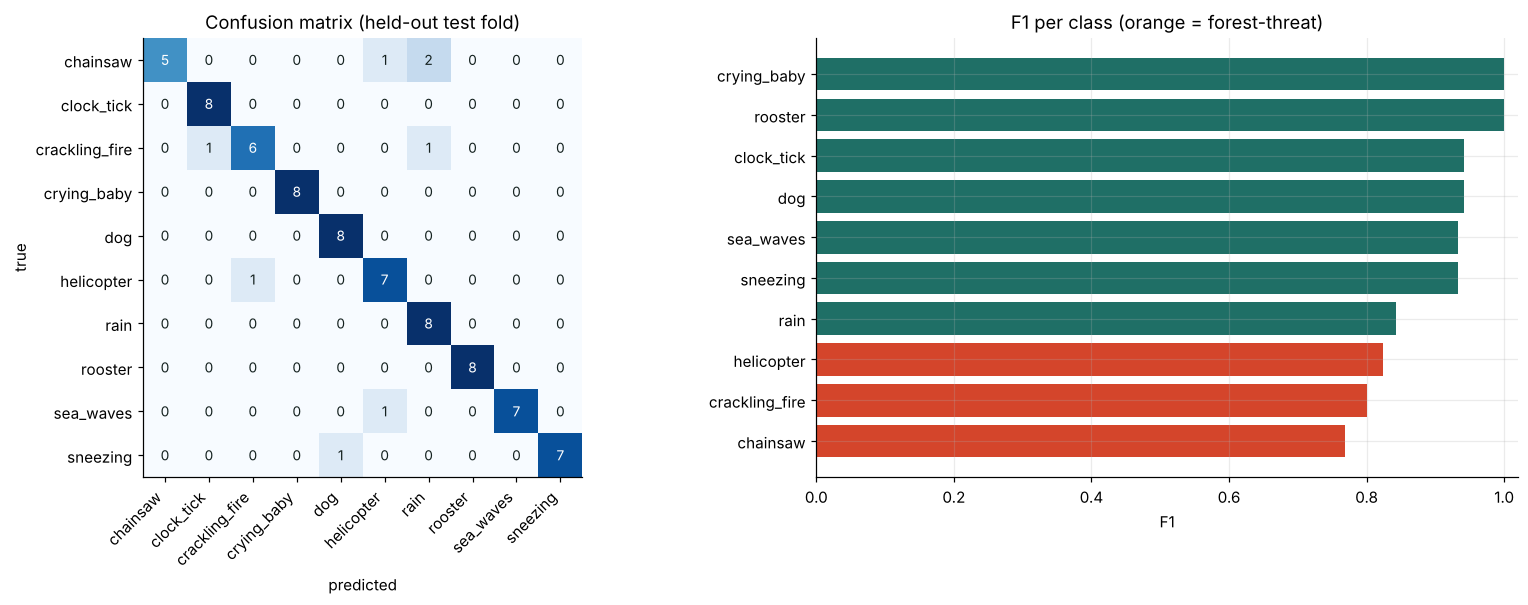

most confused pairs (errors in both directions): [('chainsaw', 'rain', 2), ('helicopter', 'sea_waves', 1), ('dog', 'sneezing', 1)]


In [10]:
rep = pd.DataFrame(test_m["per_class"]).T.round(3)
rep["threat"] = [c in C.ALERT_CLASSES for c in rep.index]
display(rep)

cm = np.array(test_m["confusion_matrix"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax[0].imshow(cm, cmap="Blues"); ax[0].grid(False)
ax[0].set_xticks(range(n)); ax[0].set_xticklabels(classes, rotation=45, ha="right"); ax[0].set_yticks(range(n)); ax[0].set_yticklabels(classes)
for i in range(n):
    for j in range(n):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=9)
ax[0].set_xlabel("predicted"); ax[0].set_ylabel("true"); ax[0].set_title("Confusion matrix (held-out test fold)")
f1 = rep["f1"].sort_values()
ax[1].barh(f1.index, f1.values, color=[ORANGE if c in C.ALERT_CLASSES else TEAL for c in f1.index])
ax[1].set_xlim(0, 1.02); ax[1].set_title("F1 per class (orange = forest-threat)"); ax[1].set_xlabel("F1")
plt.tight_layout(); plt.savefig(FIG / "evaluation.png"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j] + off[j, i], classes[i], classes[j]) for i in range(n) for j in range(i + 1, n)], reverse=True)
print("most confused pairs (errors in both directions):", [(a, b, int(k)) for k, a, b in pairs[:3] if k > 0])

### What the metrics say
The optimised model should beat the baseline on every metric above, and the per-class table shows where it still struggles.
The group we flagged from the feature analysis (continuous, noise-like sounds: chainsaw, rain, sea waves) is
checked directly in the last line of the previous cell. In our run the most-confused pair was chainsaw vs rain, which fits that prediction.

**Threat-detection view.** For a field alert system, recall on the threat classes matters most (a missed chainsaw is
worse than a false alarm), so we also report it on its own:

In [11]:
thr = [c for c in classes if c in C.ALERT_CLASSES]
tp = sum(cm[classes.index(c), classes.index(c)] for c in thr); tot = sum(cm[classes.index(c)].sum() for c in thr)
pred_thr = sum(cm[:, classes.index(c)].sum() for c in thr)
print(f"threat-class recall    : {tp/tot:.3f}   ({tp}/{tot} threat clips assigned to the right threat class)")
tpa = sum(cm[classes.index(a), classes.index(b)] for a in thr for b in thr)
print(f"'any threat' recall    : {tpa/tot:.3f}   (threat clip flagged as *some* threat)")
fa = sum(cm[classes.index(a), classes.index(b)] for a in classes if a not in thr for b in thr)
print(f"false alarms           : {fa} of {sum(cm[classes.index(a)].sum() for a in classes if a not in thr)} harmless clips")

threat-class recall    : 0.750   (18/24 threat clips assigned to the right threat class)
'any threat' recall    : 0.833   (threat clip flagged as *some* threat)
false alarms           : 1 of 56 harmless clips


## 6. Save the model and test the prediction function

`save_version` writes `models/forestear_v1.h5`, records metrics in `models/registry.json` and copies the promoted file to
`models/forestear_model.h5`. The API loads whatever the registry marks as current, and hot-reloads when retraining promotes a new version.

In [12]:
entry = M.save_version(model, classes, test_m, best["params"], trigger="notebook", promote=True,
                       extra={"mode": "scratch", "train_clips": int(len(Xtr)), "val_clips": int(len(Xva)),
                              "baseline_test_accuracy": base_test["accuracy"]})
print("saved:", entry["file"], "| classes:", len(entry["classes"]), "| test acc:", round(entry["metrics"]["accuracy"], 3))
print(sorted(p.name for p in C.MODELS_DIR.glob("*")))

saved: forestear_v1.h5 | classes: 10 | test acc: 0.9
['forestear_model.h5', 'forestear_v1.h5', 'registry.json']


In [13]:
from src.prediction import Predictor
predictor = Predictor()                      # what the API uses: loads the saved .h5, not the in-memory model
rng = np.random.default_rng(1)
rows = []
for idx in rng.choice(len(test_clips), 10, replace=False):
    path, truth = test_clips[idx]
    r = predictor.predict(str(path))
    rows.append({"file": path.name, "true": truth, "predicted": r["label"], "confidence": round(r["confidence"], 3),
                 "correct": r["label"] == truth, "alert": r["alert"], "ms": r["latency_ms"]})
display(pd.DataFrame(rows))

# sanity check: the reloaded model must reproduce the in-memory metrics
acc = np.mean([predictor.predict(str(p))["label"] == c for p, c in test_clips])
print(f"accuracy through Predictor on the full test fold: {acc:.3f}  (evaluate() said {test_m['accuracy']:.3f})")

,file,true,predicted,confidence,correct,alert,ms
0,5-151085-A-20.wav,crying_baby,crying_baby,0.909,True,False,190.2
1,5-203128-B-0.wav,dog,dog,0.972,True,False,70.0
2,5-234879-B-1.wav,rooster,rooster,0.989,True,False,73.3
3,5-171653-A-41.wav,chainsaw,chainsaw,0.886,True,True,69.6
4,5-194533-A-21.wav,sneezing,sneezing,0.823,True,False,70.7
5,5-213855-A-0.wav,dog,dog,0.990,True,False,75.0
6,5-209698-A-38.wav,clock_tick,clock_tick,0.605,True,False,119.1
7,5-203739-A-10.wav,rain,rain,0.802,True,False,115.0
8,5-219379-B-11.wav,sea_waves,sea_waves,0.925,True,False,137.8
9,5-193473-A-12.wav,crackling_fire,crackling_fire,0.572,True,True,136.3


accuracy through Predictor on the full test fold: 0.900  (evaluate() said 0.900)


## 7. Retraining readiness

Retraining never starts from scratch unless asked: it **fine-tunes the saved model** (our own pre-trained network).
`transfer_weights` copies every shared layer by name and, when a *new class* appears, copies the old head rows and gives only the new
class a fresh row. The check below proves the child starts exactly where the parent stopped.

In [14]:
parent, pentry = M.load_current()
child = M.build_cnn(n + 1, **pentry["params"])
M.transfer_weights(parent, child, classes, classes + ["new_sound"])
pp = M.predict_proba(parent, Xte); cp = M.predict_proba(child, Xte)
same = np.mean(pp.argmax(1) == cp.argmax(1))
print(f"child (n+1 classes, before any training) agrees with parent on {same:.1%} of test clips")
print("shared backbone identical:", all(np.allclose(a, b) for la in parent.layers if la.name.startswith("conv")
      for a, b in zip(la.get_weights(), child.get_layer(la.name).get_weights())))

child (n+1 classes, before any training) agrees with parent on 100.0% of test clips
shared backbone identical: True


In production the full loop is: **upload clips -> saved to `data/uploads/` and the SQLite table `uploads` -> preprocessing ->
`fine_tune` on train + all uploads -> evaluate on the fixed test fold -> promote only if macro-F1 is within 3 points of the champion.**
It is triggered by the *Retrain* button, or automatically when enough new clips arrive or live confidence drifts down
(see `src/retrain.py` and the README).

## 8. Limitations and next steps
* ESC-10 is small (400 clips) and recorded by many people with many microphones. Real forest nodes will have wind, rain, insects
  and a different microphone, so the first thing to do after deployment is to upload field clips and retrain.
* A model that only knows 10 sounds will force every new sound into one of them. The *low-confidence* flag in the API and UI is the safety net,
  and uploading a new class with the UI extends the model.
* Next: a pretrained audio embedding (e.g. YAMNet / PANNs), longer recordings with sliding windows, and on-device inference.